# Giai đoạn 10 — Các trang ứng dụng Streamlit dạng notebook + kiểm thử tự động

App thật vẫn là các file `.py` trong `product_v3/app_pages/`, vì Streamlit chỉ chạy được file `.py`.
Notebook này **viết lại logic của từng trang** để xem bảng và biểu đồ ngay trong notebook, không cần mở trình duyệt.
Cuối notebook, **AppTest** chạy chính các file `.py` (headless) để bắt lỗi trước khi deploy.

Chạy app thật: `streamlit run product_v3/Home.py`

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np, pandas as pd, joblib

PRODUCT = os.path.abspath("product_v3")          # notebook chạy từ thư mục Notebook/
if PRODUCT not in sys.path:
    sys.path.insert(0, PRODUCT)
import core                                       # bản .py mà app Streamlit dùng
print("core.py:", core.__file__)
print("Mô hình:", core.MODEL_NAME)

core.py: D:\2.Code\3.DATT_2026_Ver2\Notebook\product_v3\core.py
Mô hình: Phân loại: MLP(16,8) + log(V) + one-hot loại đất · Phát hiện: HistGradientBoosting nhị phân


In [2]:
import altair as alt
core._cache.clear()
meta = core.load_bundle()["meta"]            # tự huấn luyện nếu chưa có model.pkl
sample = pd.read_excel(os.path.join(PRODUCT, "data", "sample_batch.xlsx"))
pred, _ = core.predict_batch(sample)

## Trang chủ (`0_Home_page.py`) — thông tin mô hình

In [3]:
pd.Series({k: v for k, v in meta.items() if k not in ("classes", "features")}).to_frame("giá trị")

,giá trị
model_name,"Phân loại: MLP(16,8) + log(V) + one-hot loại đ..."
cv_accuracy,71.8
cv_accuracy_std,4.6
macro_f1_cv,71.0
top2_accuracy_cv,88.3
detect_recall_cv,92.6
safe_threshold,0.0972
test_recall_mean,99.4
test_recall_std,1.0
hold_100_rate,75.0


## Dự đoán hàng loạt (`1_Du_doan_hang_loat.py`)

In [4]:
s = core.summarize(pred)
print(f"Tổng tín hiệu: {s['tong_tin_hieu']} | Ưu tiên cao: {s['uu_tien_cao']} | "
      f"Ưu tiên thấp (xếp cuối): {s['uu_tien_thap']} ({s['ty_le_uu_tien_thap']}%)")
STYLE = {"Rất cao": "background-color:#e53935;color:#fff;font-weight:700",
         "Cao": "background-color:#fb8c00;color:#1a1a1a;font-weight:700",
         "Trung bình": "background-color:#fdd835;color:#1a1a1a",
         "Thấp": "background-color:#43a047;color:#fff"}
cols = ["id", "V", "H", "S", "xac_suat_co_min", "loai_du_doan", "loai_kha_nang_2", "muc_uu_tien", "hang_uu_tien"]
chosen = ["Rất cao", "Cao", "Trung bình", "Thấp"]          # bộ lọc mức ưu tiên
pred[pred["muc_uu_tien"].isin(chosen)][cols].head(15).style.map(lambda v: STYLE.get(v, ""), subset=["muc_uu_tien"])

Tổng tín hiệu: 338 | Ưu tiên cao: 302 | Ưu tiên thấp (xếp cuối): 36 (10.7%)


,id,V,H,S,xac_suat_co_min,loai_du_doan,loai_kha_nang_2,muc_uu_tien,hang_uu_tien
0,TH0051,0.906343,0.363636,0.000000,1.000000,Mìn chống tăng,Mìn chống bộ binh bẫy,Rất cao,1
1,TH0052,0.658609,0.545455,0.000000,1.000000,Mìn chống tăng,Mìn chống bộ binh bẫy,Rất cao,2
2,TH0053,0.610271,0.636364,0.000000,1.000000,Mìn chống tăng,Mìn chống bộ binh bẫy,Rất cao,3
3,TH0054,0.453172,0.818182,0.000000,1.000000,Mìn chống tăng,Mìn chống bộ binh bẫy,Rất cao,4
4,TH0055,0.442447,0.909091,0.000000,1.000000,Mìn chống tăng,Mìn chống bộ binh bẫy,Rất cao,5
5,TH0058,0.975830,0.272727,0.600000,1.000000,Mìn chống tăng,Mìn chống bộ binh,Rất cao,6
6,TH0059,0.815709,0.363636,0.600000,1.000000,Mìn chống tăng,Mìn chống bộ binh,Rất cao,7
7,TH0060,0.655588,0.545455,0.600000,1.000000,Mìn chống tăng,Mìn chống bộ binh,Rất cao,8
8,TH0061,0.628398,0.636364,0.600000,1.000000,Mìn chống tăng,Mìn chống bộ binh,Rất cao,9
9,TH0062,0.504531,0.818182,0.600000,1.000000,Mìn chống tăng,Mìn chống bộ binh,Rất cao,10


## Bản đồ rủi ro (`2_Ban_do_rui_ro.py`)

In [5]:
LEVELS = ["Rất cao", "Cao", "Trung bình", "Thấp"]; COLORS = ["#e53935", "#fb8c00", "#fdd835", "#43a047"]
alt.Chart(pred.dropna(subset=["x", "y"])).mark_circle(opacity=0.85, stroke="#333", strokeWidth=0.4).encode(
    x=alt.X("x:Q", title="Tọa độ X", scale=alt.Scale(zero=False)),
    y=alt.Y("y:Q", title="Tọa độ Y", scale=alt.Scale(zero=False)),
    size=alt.Size("xac_suat_co_min:Q", title="P(có mìn)", scale=alt.Scale(range=[40, 500])),
    color=alt.Color("muc_uu_tien:N", title="Mức ưu tiên", scale=alt.Scale(domain=LEVELS, range=COLORS), sort=LEVELS),
    tooltip=["id", "loai_du_doan", "loai_kha_nang_2", alt.Tooltip("xac_suat_co_min:Q", format=".3f"), "hang_uu_tien"],
).properties(width=650, height=450).interactive()

alt.Chart(...)

## Tổng quan (`3_Tong_quan.py`)

In [6]:
order = ["Rất cao", "Cao", "Trung bình", "Thấp"]
dist = pred["muc_uu_tien"].value_counts().reindex(order).fillna(0).rename_axis("Mức").reset_index(name="Số lượng")
c1 = alt.Chart(dist).mark_bar().encode(x=alt.X("Mức", sort=order), y="Số lượng",
        color=alt.Color("Mức", scale=alt.Scale(domain=order, range=COLORS), legend=None)).properties(width=300, height=250)
typ = pred["loai_du_doan"].value_counts().rename_axis("Loại").reset_index(name="Số lượng")
c2 = alt.Chart(typ).mark_arc(innerRadius=50).encode(theta="Số lượng", color="Loại", tooltip=["Loại", "Số lượng"]).properties(width=250, height=250)
c3 = alt.Chart(pred).mark_bar().encode(x=alt.X("xac_suat_co_min", bin=alt.Bin(maxbins=20), title="P(có mìn)"),
        y=alt.Y("count()", title="Số tín hiệu")).properties(width=600, height=200)
(c1 | c2) & c3

alt.VConcatChart(...)

In [7]:
tmp = pred.assign(**{"Loại đất": pred["S"].round(1).map(core.SOIL_NAMES)})
tmp.groupby("Loại đất").agg(**{"Số tín hiệu": ("S", "size"), "P(có mìn) TB %": ("xac_suat_co_min", lambda v: round(v.mean()*100, 1))})

,Số tín hiệu,P(có mìn) TB %
Loại đất,,
Khô & cát,59,80.6
Khô & mùn,51,76.4
Khô & vôi,56,77.0
Ẩm & cát,57,80.1
Ẩm & mùn,58,77.9
Ẩm & vôi,57,81.6


## Thử đơn lẻ (`4_Thu_don_le.py`) — đổi V, H, S rồi chạy lại ô

Loại đất: Ẩm & cát | Dự đoán: Không mìn (khả năng 2: Mìn chống bộ binh bẫy)
P(có mìn) = 1.4% -> ưu tiên Thấp


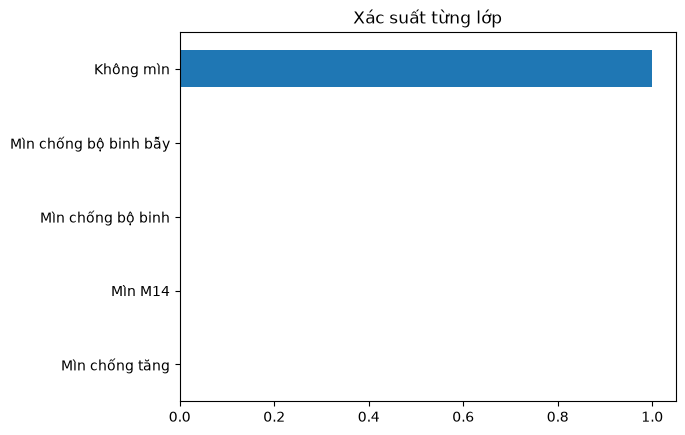

In [8]:
V, H, S = 0.30, 0.50, 0.6            # <- sửa ở đây (S ∈ {0.0, 0.2, …, 1.0})
one, _ = core.predict_batch(pd.DataFrame([{"V": V, "H": H, "S": S}]))
r = one.iloc[0]
print(f"Loại đất: {core.SOIL_NAMES[S]} | Dự đoán: {r['loai_du_doan']} (khả năng 2: {r['loai_kha_nang_2']})")
print(f"P(có mìn) = {r['xac_suat_co_min']:.1%} -> ưu tiên {r['muc_uu_tien']}")
pipe = core.load_bundle()["pipeline"]
pd.Series(pipe.predict_proba([[V, H, S]])[0], index=[core.CLASS_NAMES[c] for c in pipe.classes_]).sort_values().plot.barh(title="Xác suất từng lớp");

In [9]:
# Độ nhạy: P(có mìn) theo V ở từng loại đất (H = 0,3) — để thấy mô hình phản ứng có hợp lý không
grid = pd.DataFrame([{"V": v, "H": 0.3, "S": s} for s in core.SOIL_NAMES for v in np.linspace(0.05, 1, 40)])
grid["P(có mìn)"] = core.p_mine_of(core.load_bundle()["detector"], grid[["V", "H", "S"]].values)
grid["Loại đất"] = grid["S"].map(core.SOIL_NAMES)
alt.Chart(grid).mark_line().encode(x="V", y="P(có mìn)", color="Loại đất").properties(width=550, height=280)

alt.Chart(...)

## Kiểm thử tự động các trang thật (Streamlit AppTest)

Chạy chính các file `.py` của app ở chế độ headless: bấm nút, đổi bộ lọc, rồi kiểm tra không có exception.

In [10]:
from streamlit.testing.v1 import AppTest
os.chdir(PRODUCT)
def check(name, at):
    errs = [e.value for e in at.exception] + [e.value for e in at.error]
    print(f"{'✓' if not errs else '✗'} {name:34s} {errs if errs else ''}")
    return not errs
ok = []
ok.append(check("Home.py (st.navigation)", AppTest.from_file("Home.py", default_timeout=120).run()))
ok.append(check("0_Home_page", AppTest.from_file("app_pages/0_Home_page.py", default_timeout=120).run()))
at = AppTest.from_file("app_pages/1_Du_doan_hang_loat.py", default_timeout=120).run()
at.button[0].click().run(); ok.append(check("1_Du_doan_hang_loat (file mẫu)", at))
n_all = len(at.dataframe[0].value)
at.multiselect[0].set_value(["Rất cao"]).run(); ok.append(check("1_Du_doan_hang_loat (đổi bộ lọc)", at))
print(f"   bảng: {n_all} dòng -> lọc 'Rất cao': {len(at.dataframe[0].value)} dòng")
for f in ["2_Ban_do_rui_ro.py", "3_Tong_quan.py"]:
    at = AppTest.from_file(f"app_pages/{f}", default_timeout=120); at.session_state["pred"] = pred
    ok.append(check(f, at.run()))
at = AppTest.from_file("app_pages/4_Thu_don_le.py", default_timeout=120).run()
at.button[0].click().run(); ok.append(check("4_Thu_don_le (bấm Dự đoán)", at))
os.chdir(os.path.dirname(PRODUCT))
assert all(ok), "Có trang lỗi — xem dòng ✗ ở trên"
print("\nTất cả", len(ok), "kiểm thử đều qua.")

2026-10-20 17:15:56.474 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-20 17:15:56.521 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✓ Home.py (st.navigation)            


2026-10-20 17:15:56.909 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✓ 0_Home_page                        


...

2026-10-20 17:15:57.341 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-20 17:15:57.342 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✓ 1_Du_doan_hang_loat (file mẫu)     
✓ 1_Du_doan_hang_loat (đổi bộ lọc)   
   bảng: 338 dòng -> lọc 'Rất cao': 264 dòng
✓ 2_Ban_do_rui_ro.py                 


2026-10-20 17:15:57.385 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✓ 3_Tong_quan.py                     
✓ 4_Thu_don_le (bấm Dự đoán)         

Tất cả 7 kiểm thử đều qua.
